In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import nltk
import re
import string

# Download NLTK data (run once)
nltk.download('stopwords')
nltk.download('punkt')

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

print("All libraries imported successfully!")

[nltk_data] Downloading package stopwords to C:\Users\Utkarsh
[nltk_data]     Jain\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package punkt to C:\Users\Utkarsh
[nltk_data]     Jain\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.


All libraries imported successfully!


In [10]:
# Load both CSVs
true_df  = pd.read_csv('../data/True.csv')
fake_df  = pd.read_csv('../data/Fake.csv')

# Add labels — 1 = real, 0 = fake
true_df['label'] = 1
fake_df['label'] = 0

# Combine into one dataframe
df = pd.concat([true_df, fake_df], ignore_index=True)

# Shuffle the rows (important for training later)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nFirst 3 rows:")
df.head(3)

Shape: (44898, 5)

Columns: ['title', 'text', 'subject', 'date', 'label']

First 3 rows:


,title,text,subject,date,label
0,BREAKING: GOP Chairman Grassley Has Had Enoug...,"Donald Trump s White House is in chaos, and th...",News,"July 21, 2017",0
1,Failed GOP Candidates Remembered In Hilarious...,Now that Donald Trump is the presumptive GOP n...,News,"May 7, 2016",0
2,Mike Pence’s New DC Neighbors Are HILARIOUSLY...,Mike Pence is a huge homophobe. He supports ex...,News,"December 3, 2016",0


In [11]:
print("Dataset info:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df['label'].value_counts())
print(f"\nReal news: {df['label'].sum()} articles")
print(f"Fake news: {(df['label']==0).sum()} articles")

Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    44898 non-null  str  
 1   text     44898 non-null  str  
 2   subject  44898 non-null  str  
 3   date     44898 non-null  str  
 4   label    44898 non-null  int64
dtypes: int64(1), str(4)
memory usage: 112.3 MB
None

Missing values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64

Class distribution:
label
0    23481
1    21417
Name: count, dtype: int64

Real news: 21417 articles
Fake news: 23481 articles


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import joblib

# Train the model
model = LogisticRegression()
model.fit(X_train_tfidf, y_train)

# Evaluate
predictions = model.predict(X_test_tfidf)
print(f"Accuracy: {accuracy_score(y_test, predictions)}")
print(classification_report(y_test, predictions))

# Export model and vectorizer to the 'models' folder
joblib.dump(model, '../models/fake_news_model.pkl')
joblib.dump(vectorizer, '../models/fake_news_vectorizer.pkl')

Accuracy: 0.9902004454342984
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      4741
           1       0.99      0.99      0.99      4239

    accuracy                           0.99      8980
   macro avg       0.99      0.99      0.99      8980
weighted avg       0.99      0.99      0.99      8980



['../models/fake_news_vectorizer.pkl']

C:\Users\Utkarsh Jain\AppData\Local\Temp\ipykernel_10808\454793126.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='label', data=df, palette=['#D85A30', '#1D9E75'])
C:\Users\Utkarsh Jain\AppData\Local\Temp\ipykernel_10808\454793126.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Fake', 'Real'])


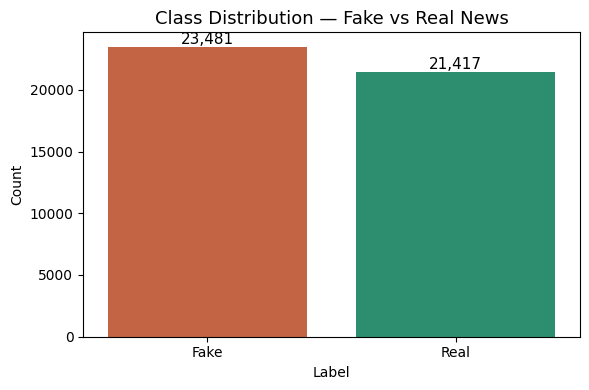

Chart saved!


In [12]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='label', data=df, palette=['#D85A30', '#1D9E75'])
ax.set_xticklabels(['Fake', 'Real'])
ax.set_title('Class Distribution — Fake vs Real News', fontsize=13)
ax.set_xlabel('Label')
ax.set_ylabel('Count')

# Add count labels on bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.savefig('../data/class_distribution_fakenews.png', dpi=150)
plt.show()
print("Chart saved!")

Average text length:
label
Fake    423.197905
Real    385.640099
Name: text_length, dtype: float64


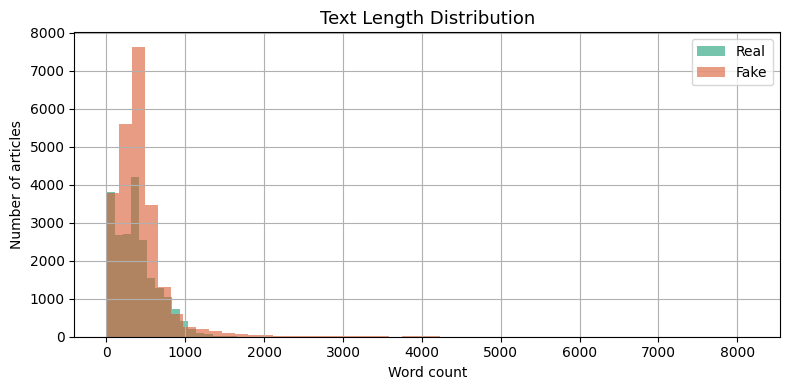

In [13]:
# Add a column for text length (word count)
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))

print("Average text length:")
print(df.groupby('label')['text_length'].mean().rename({0:'Fake', 1:'Real'}))

plt.figure(figsize=(8, 4))
df[df['label']==1]['text_length'].hist(bins=50, alpha=0.6, color='#1D9E75', label='Real')
df[df['label']==0]['text_length'].hist(bins=50, alpha=0.6, color='#D85A30', label='Fake')
plt.title('Text Length Distribution', fontsize=13)
plt.xlabel('Word count')
plt.ylabel('Number of articles')
plt.legend()
plt.tight_layout()
plt.savefig('../data/text_length_fakenews.png', dpi=150)
plt.show()

In [8]:
# Train the spam model
spam_model = LogisticRegression()
spam_model.fit(X_train_tfidf_s, y_train_s)

# Evaluate
spam_predictions = spam_model.predict(X_test_tfidf_s)
print(f"Spam Model Accuracy: {accuracy_score(y_test_s, spam_predictions)}")
print(classification_report(y_test_s, spam_predictions))

# Export model and vectorizer
joblib.dump(spam_model, '../models/spam_model.pkl')
joblib.dump(spam_vectorizer, '../models/spam_vectorizer.pkl')

Spam Model Accuracy: 0.9668161434977578
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       965
           1       1.00      0.75      0.86       150

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.96      1115



['../models/spam_vectorizer.pkl']

In [14]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text):
    # 1. Lowercase
    text = text.lower()
    # 2. Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    # 3. Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)
    # 4. Tokenize (split into words)
    words = text.split()
    # 5. Remove stopwords and stem
    words = [stemmer.stem(w) for w in words if w not in stop_words and len(w) > 2]
    return ' '.join(words)

# Apply to the text column
df['clean_text'] = df['text'].apply(clean_text)

print("Original text sample:")
print(df['text'].iloc[0][:200])
print("\nCleaned text sample:")
print(df['clean_text'].iloc[0][:200])

Original text sample:
Donald Trump s White House is in chaos, and they are trying to cover it up. Their Russia problems are mounting by the hour, and they refuse to acknowledge that there are problems surrounding all of th

Cleaned text sample:
donald trump white hous chao tri cover russia problem mount hour refus acknowledg problem surround fake news hoax howev fact bear thing differ seem crack congression public leadershipchuck grassley ri


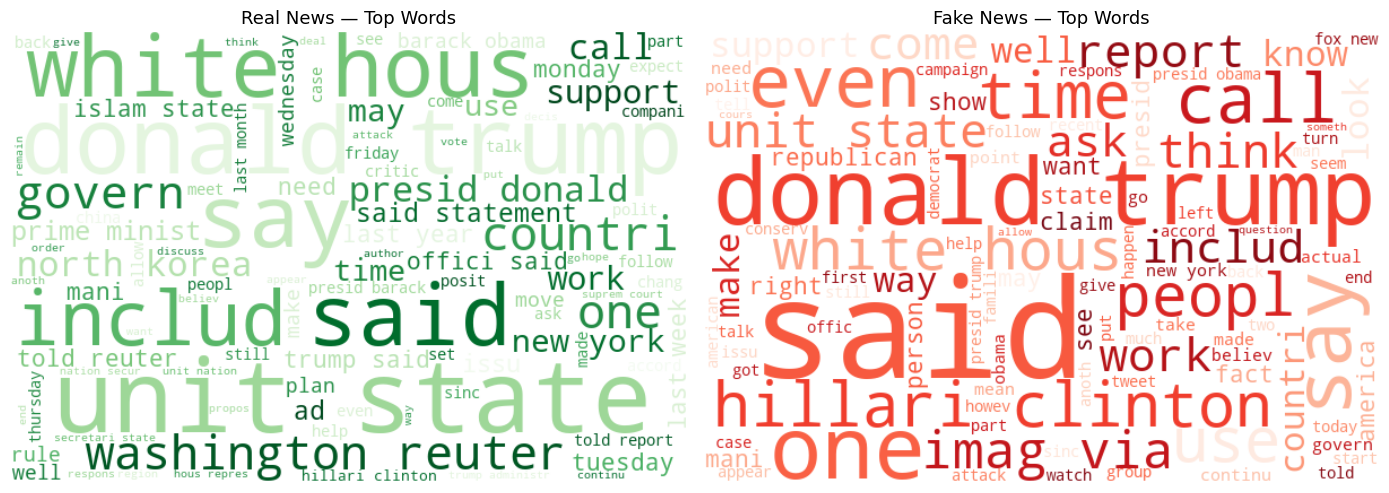

Word clouds saved!


In [15]:
# Real news wordcloud
real_text = ' '.join(df[df['label']==1]['clean_text'])
fake_text = ' '.join(df[df['label']==0]['clean_text'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

wc_real = WordCloud(width=600, height=400, background_color='white',
                    colormap='Greens', max_words=100).generate(real_text)
axes[0].imshow(wc_real, interpolation='bilinear')
axes[0].set_title('Real News — Top Words', fontsize=13)
axes[0].axis('off')

wc_fake = WordCloud(width=600, height=400, background_color='white',
                    colormap='Reds', max_words=100).generate(fake_text)
axes[1].imshow(wc_fake, interpolation='bilinear')
axes[1].set_title('Fake News — Top Words', fontsize=13)
axes[1].axis('off')

plt.tight_layout()
plt.savefig('../data/wordclouds_fakenews.png', dpi=150)
plt.show()
print("Word clouds saved!")

In [16]:
df.to_csv('../data/fake_news_cleaned.csv', index=False)
print(f"Cleaned dataset saved — {len(df)} rows, {df.shape[1]} columns")
print("Columns:", df.columns.tolist())

Cleaned dataset saved — 44898 rows, 7 columns
Columns: ['title', 'text', 'subject', 'date', 'label', 'text_length', 'clean_text']
